# PS4 — Statystyka opisowa, część 2
### Sprawozdanie 1, max. 20 pkt.
**Statystyka Matematyczna — Data Science**  

**Imię i nazwisko:** Marcin Zubowski  
**Imię i nazwisko:** Borys Maksymiuk  
**Grupa:** PS2 **Data:** 26.10.2026

**Cel:** połączyć miary położenia i wykresy z części 1 z miarami rozproszenia, zróżnicowania, asymetrii i koncentracji. Samodzielnie porównać **dwie cechy ilościowe** z tego samego zbioru.

**Zasada:** komórki kodu zawierają wskazówki, nie pełne rozwiązania. Każdy wynik liczbowy należy zinterpretować w kontekście danych.

## 0. Pobranie i wczytanie danych z Kaggle
1. Wejdź na [Kaggle Datasets](https://www.kaggle.com/datasets) i wybierz zbiór zawierający **co najmniej 100 obserwacji i dwie sensowne cechy ilościowe** (najlepiej dodatnie, ze skalą ilorazową).
2. Pobierz plik CSV (`Download`), rozpakuj archiwum ZIP, jeśli trzeba, i umieść plik CSV **w folderze notebooka**.
3. Uzupełnij nazwę pliku w kodzie. **Nie używaj danych symulowanych.** Jeśli plik ma separator `;` lub nietypowe kodowanie, zmień parametry `read_csv`.
4. Wpisz poniżej: nazwę zbioru, link do strony Kaggle, autora, krótki opis źródła i jednostkę statystyczną.

**Nazwa:** UZUPEŁNIJ  
**autor:** UZUPEŁNIJ  
**URL:** UZUPEŁNIJ  
**opis:** UZUPEŁNIJ  
**Jednostka statystyczna:** UZUPEŁNIJ

In [2]:
# Jeśli biblioteki nie są zainstalowane, uruchom osobno: %pip install pandas numpy matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plik = "USvideos.csv"  # np. dane.csv — plik z folderu notebooka
df = pd.read_csv(plik)   # w razie potrzeby: sep=";", decimal=",", encoding="utf-8"
display(df.head())
print("Wymiary:", df.shape)
print("Kolumny i typy:")
print(df.dtypes)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


Wymiary: (40949, 16)
Kolumny i typy:
video_id                    str
trending_date               str
title                       str
channel_title               str
category_id               int64
publish_time                str
tags                        str
views                     int64
likes                     int64
dislikes                  int64
comment_count             int64
thumbnail_link              str
comments_disabled          bool
ratings_disabled           bool
video_error_or_removed     bool
description                 str
dtype: object


In [3]:
# Zbadaj braki danych i duplikaty; uzupełnij:
braki = df.isna().sum()   # df.isna().sum()
duplikaty = df.duplicated().sum()  # df.duplicated().sum()
print(braki)
print("Duplikaty:", duplikaty)

video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
description               570
dtype: int64
Duplikaty: 48


### Najpierw pomyśl
- Co reprezentuje **jeden wiersz**? Co oznaczają kolumny?
- Ile jest wierszy i kolumn? Czy występują braki danych i duplikaty?
- Czy dane dotyczą próby, czy całej badanej zbiorowości? Czy można je uogólniać?

**Odpowiedź:** 

- Jeden wiersz reprezentuje jeden film na plotformie YouTube.
- Jest 40949 wierszy oraz 16 kolumn. Braki występują dla cechy "description" (opis). Występuje również 48 duplikatów.
- Dane dotyczą pojedynczej próby

## 1. Wybór dwóch cech i przygotowanie danych
Wybierz **dwie kolumny liczbowe**, które mają sens merytoryczny. Podaj ich znaczenie i jednostki. Nie wybieraj identyfikatorów ani kodów kategorii zapisanych liczbami.

**Cecha X:** Views — liczba wyświetleń filmu, wyświetlenie  
**Cecha Y:** Likes — liczba polubień film, polubienie

Przygotuj obie kolumny jako liczby. Usuń braki **wspólnie dla obu cech**, aby porównywać te same obserwacje. Udokumentuj, ile wierszy usunięto. Nie usuwaj wartości odstających bez uzasadnienia.

In [4]:
kol_x = "views"  # dokładna nazwa kolumny z df.columns
kol_y = "likes"

wybrane = df[[kol_x, kol_y]].copy()
wybrane[kol_x] = pd.to_numeric(wybrane[kol_x], errors="coerce")
wybrane[kol_y] = pd.to_numeric(wybrane[kol_y], errors="coerce")
dane = wybrane.dropna()
x = dane[kol_x].to_numpy()
y = dane[kol_y].to_numpy()
print("Przed:", len(df), "Po:", len(dane), "Usunięto:", len(df)-len(dane))
assert len(dane) >= 100, "Wybierz zbiór z co najmniej 100 kompletnymi obserwacjami"
display(dane.head())

Przed: 40949 Po: 40949 Usunięto: 0


,views,likes
0,748374,57527
1,2418783,97185
2,3191434,146033
3,343168,10172
4,2095731,132235


## 2. Powtórzenie z części 1 — miary położenia
Dla **obu cech** oblicz: liczebność, minimum, maksimum, średnią, medianę, dominantę (jeśli jest interpretowalna), Q1, Q3. Kwartyle licz metodą `np.quantile(..., method="linear")`. Zestaw wyniki w jednej tabeli.

In [12]:
# UZUPEŁNIJ: napisz funkcję lub zbuduj tabelę z użyciem pandas / numpy.
# Przykładowe wskazówki: np.mean(x), np.median(x), np.quantile(x, 0.25, method="linear")
X = dane[kol_x]
Y = dane[kol_y]
miary_polozenia = pd.DataFrame({
    "miara": ["n", "min", "max", "średnia", "mediana", "dominanta", "Q1", "Q3"],
    "X": [len(X), X.min(), X.max(), X.mean(), X.median(), X.mode()[0], np.quantile(X, q=0.25, method="linear"), np.quantile(X, q=0.75, method="linear")],  # uzupełnij ośmioma wartościami
    "Y": [len(Y), Y.min(), Y.max(), Y.mean(), Y.median(), Y.mode()[0], np.quantile(Y, q=0.25, method="linear"), np.quantile(Y, q=0.25, method="linear")]
})
display(miary_polozenia)

,miara,X,Y
0,n,4.094900e+04,4.094900e+04
1,min,5.490000e+02,0.000000e+00
2,max,2.252119e+08,5.613827e+06
3,średnia,2.360785e+06,7.426670e+04
4,mediana,6.818610e+05,1.809100e+04
5,dominanta,2.078000e+03,0.000000e+00
6,Q1,2.423290e+05,5.424000e+03
7,Q3,1.823157e+06,5.424000e+03


**Interpretacja (3–5 zdań):** Czy średnia i mediana są blisko siebie? Która z nich lepiej opisuje typową wartość? Czy dominanta dla danych ciągłych ma sens? Zinterpretuj pozostałe miary położenia.

UZUPEŁNIJ

## 3. Wykresy: histogramy, wykresy kołowe i boxploty
1. Narysuj **histogram każdej cechy** (dobierz liczbę klas i opisz osie). Zaznacz średnią i medianę.
2. Narysuj **dwa wykresy kołowe** udziałów obserwacji w 4–6 **rozłącznych przedziałach wartości**. Zbuduj przedziały przez `pd.cut` i policz udziały. Nie rysuj koła dla każdej pojedynczej wartości liczbowej!
3. Narysuj **boxploty** obu cech. Zinterpretuj medianę, IQR, wąsy i punkty odstające. Wyjaśnij, dlaczego koła mogą być mniej czytelne niż histogramy.

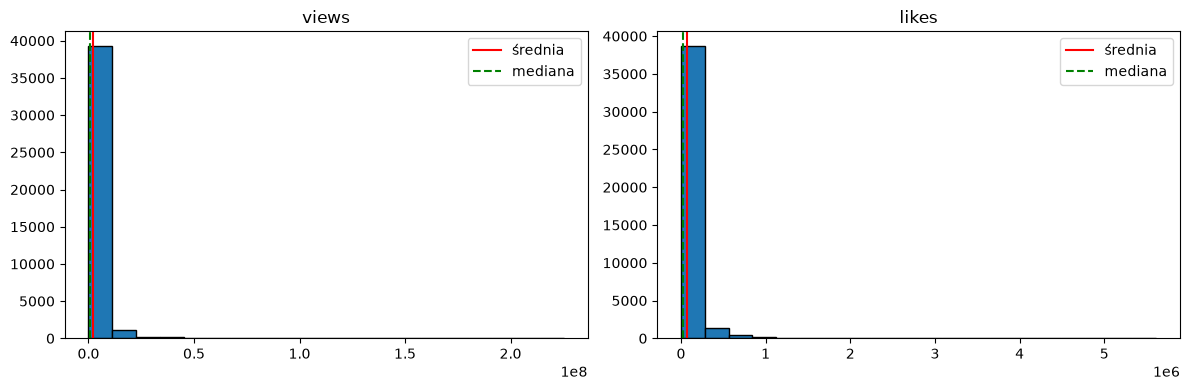

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].hist(X, bins=20, edgecolor="black")
ax[0].axvline(X.mean(), color="red", label="średnia")
ax[0].axvline(X.median(), color="green", linestyle="--", label="mediana")
ax[0].set_title(kol_x)
ax[0].legend()
# UZUPEŁNIJ: histogram Y, podpisy osi i legenda
ax[1].hist(Y, bins=20, edgecolor="black")
ax[1].axvline(Y.mean(), color="red", label="średnia")
ax[1].axvline(Y.median(), color="green", linestyle="--", label="mediana")
ax[1].set_title(kol_y)
ax[1].legend()

plt.tight_layout(); plt.show()

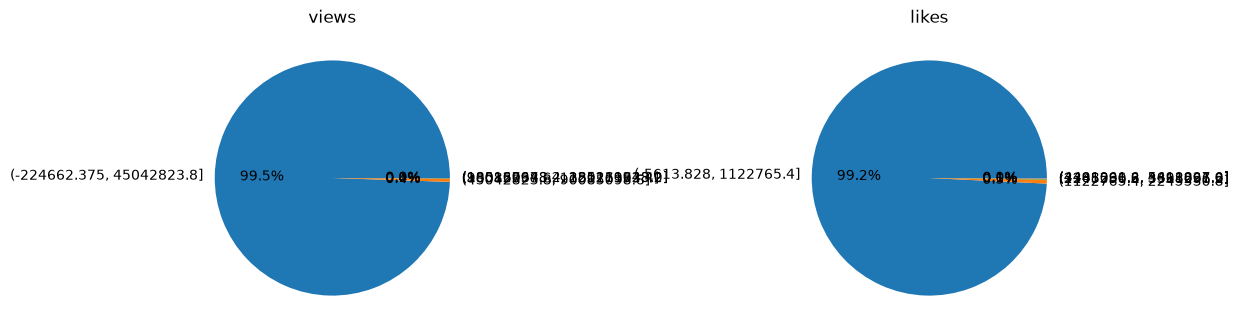

In [28]:
# Wykresy kołowe: 4–6 przedziałów dla każdej cechy
fig, ax = plt.subplots(1, 2, figsize=(12,5))
for a, wartosci, nazwa in zip(ax, [X, Y], [kol_x, kol_y]):
    grupy = pd.cut(wartosci, bins=5, include_lowest=True)  # np. 5
    udzialy = pd.Series(grupy).value_counts(sort=False)
    a.pie(udzialy, labels=udzialy.index, autopct="%1.1f%%")
    a.set_title(nazwa)
plt.tight_layout(); plt.show()

/tmp/ipykernel_215081/2475152536.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0] = plt.boxplot(X, vert=False)
/tmp/ipykernel_215081/2475152536.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1] = plt.boxplot(Y, vert=False)


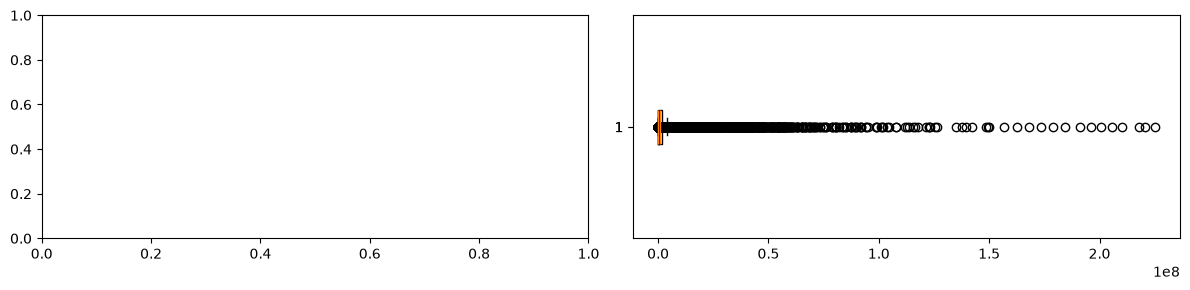

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(12,3))
# UZUPEŁNIJ: plt.boxplot dla X i Y na osobnych osiach
ax[0] = plt.boxplot(X, vert=False)
ax[1] = plt.boxplot(Y, vert=False)
plt.tight_layout(); plt.show()

**Wnioski o kształcie i wykresach:** UZUPEŁNIJ

## 4. Klasyczne miary rozproszenia — obliczenia krok po kroku
Dla obu cech wyznacz:
- rozstęp $R=\max-\min$;
- sumę kwadratów odchyleń $\sum_i(x_i-\bar x)^2$;
- wariancję opisową $S^2=\frac1n\sum_i(x_i-\bar x)^2$ oraz odchylenie $S$;
- wariancję z poprawką $\hat S^2=\frac1{n-1}\sum_i(x_i-\bar x)^2$ i $\hat S$.

**Ważne:** nie ograniczaj się do `.describe()`; przynajmniej dla jednej cechy pokaż własne obliczenie ze wzoru i sprawdź je przez `np.var(..., ddof=0/1)`. Zwróć uwagę na jednostki wariancji.

In [34]:
# Obliczenia dla X — UZUPEŁNIJ
n = len(X)
R = X.max() - X.min()
srednia_x = X.mean()
odchylenia_x = X - srednia_x
suma_kwadratow_x = (odchylenia_x ** 2).sum()
S2_x = suma_kwadratow_x / n   # mianownik n
S_x = S2_x ** 0.5
Shat2_x = suma_kwadratow_x / (n-1) # mianownik n-1
Shat_x = Shat2_x ** 0.5
print("Cecha X:", kol_x)
print("R =", R)
print("S², S, Ŝ², Ŝ:", S2_x, S_x, Shat2_x, Shat_x)
print("Kontrola numpy:", np.var(x, ddof=0), np.var(x, ddof=1))

Cecha X: views
R = 225211374
S², S, Ŝ², Ŝ: 54671583144839.02 7394023.474728696 54672918291443.125 7394113.75970394
Kontrola numpy: 54671583144839.02 54672918291443.125


In [35]:
# Analogicznie policz dla Y — UZUPEŁNIJ
n = len(Y)
R = Y.max() - Y.min()
srednia_y = Y.mean()
odchylenia_y = Y - srednia_x
suma_kwadratow_y = (odchylenia_x ** 2).sum()
S2_y = suma_kwadratow_y / n   # mianownik n
S_y = S2_y ** 0.5
Shat2_y = suma_kwadratow_y / (n-1) # mianownik n-1
Shat_y = Shat2_y ** 0.5
print("Cecha Y:", kol_y)
print("R =", R)
print("S², S, Ŝ², Ŝ:", S2_y, S_y, Shat2_y, Shat_y)
print("Kontrola numpy:", np.var(x, ddof=0), np.var(x, ddof=1))

Cecha Y: likes
R = 5613827
S², S, Ŝ², Ŝ: 54671583144839.02 7394023.474728696 54672918291443.125 7394113.75970394
Kontrola numpy: 54671583144839.02 54672918291443.125


**Pytania:** Dlaczego $S^2$ i $\hat S^2$ nie są identyczne? Czy różnica jest duża w Twoim zbiorze? Dlaczego nie wolno bezpośrednio porównywać wariancji cech wyrażonych w innych jednostkach?

**Odpowiedź:** UZUPEŁNIJ

## 5. Pozycyjne miary zróżnicowania
Oblicz dla obu cech: $IQR=Q_3-Q_1$, odchylenie ćwiartkowe $Q=IQR/2$ i przedział $[Q_1,Q_3]$. Zapisz przyjętą konwencję kwartyli (`method="linear"`).

In [36]:
# UZUPEŁNIJ dla obu cech
Q1_x = np.quantile(X, q=0.25, method="linear")
Q3_x = np.quantile(X, q=0.75, method="linear")
IQR_x = Q3_x - Q1_x
Q_x = IQR_x / 2
# analogicznie dla Y
Q1_y = np.quantile(Y, q=0.25, method="linear")
Q3_y = np.quantile(Y, q=0.75, method="linear")
IQR_y = Q3_y - Q1_y
Q_y = IQR_y / 2

**Porównaj, co mówi IQR, a co rozstęp.** 

**Odpowiedź:** UZUPEŁNIJ

## 6. Współczynniki zmienności — najważniejsze porównanie
Wyznacz dla **obu cech**:

- klasyczny współczynnik $V=\frac{S}{\bar x}\cdot100\%$;
- pozycyjny współczynnik $V_Q=\frac{Q}{Me}\cdot100\%$.

Stosuj je tylko wtedy, gdy interpretacja ilorazu jest sensowna (zwłaszcza dodatnie cechy na skali ilorazowej, średnia i mediana różne od zera). Jeśli nie jest — wyjaśnij dlaczego, a nie licz bezrefleksyjnie. Porównaj także $V$ z $V_Q$ **w obrębie każdej cechy**.

In [ ]:
# UZUPEŁNIJ — skontroluj sensowność mianowników i skal pomiaru
V_x = ..................................
V_y = ..................................
VQ_x = ..................................
VQ_y = ..................................
porownanie_V = pd.DataFrame({
    "cecha": [kol_x, kol_y],
    "V [%]": [V_x, V_y],
    "V_Q [%]": [VQ_x, VQ_y]
})
display(porownanie_V)

**Interpretacja:**
1. Która cecha ma większe **zróżnicowanie względne** według $V$? Podaj konkretne wartości procentowe.
2. Czy kolejność cech jest taka sama według $V_Q$? Jeśli nie — wyjaśnij możliwą przyczynę.
3. Dlaczego porównanie samych odchyleń standardowych mogłoby wprowadzać w błąd?
4. Czy mniejszy $V$ oznacza automatycznie „lepszą” cechę? Uzasadnij.

**Odpowiedź:** UZUPEŁNIJ

## 7. Wartości odstające i odporność miar
Dla każdej cechy oblicz granice Tukeya $Q_1-1.5IQR$, $Q_3+1.5IQR$ oraz liczbę obserwacji poza nimi. Następnie dla **jednej wybranej cechy** porównaj miary $\bar x$, $Me$, $S$, $IQR$, $V$ i $V_Q$ **przed i po usunięciu obserwacji wskazanych regułą Tukeya**. Nie nadpisuj oryginalnych danych. To ćwiczenie diagnostyczne, nie zalecenie automatycznego usuwania rekordów.

In [ ]:
# UZUPEŁNIJ: funkcja zwracająca granice i maskę wartości odstających
def maska_odstajacych(a):
    q1, q3 = np.quantile(a, [0.25, 0.75], method="linear")
    iqr = q3 - q1
    dolna = .................................. # q1 - 1.5 * iqr
    gorna = ..................................
    maska = ..................................  # warunek logiczny dla wartości poza granicami
    return dolna, gorna, maska

for nazwa, a in [(kol_x, x), (kol_y, y)]:
    dol, gor, maska = maska_odstajacych(a)
    print(nazwa, "granice:", dol, gor, "odstające:", np.sum(maska))

In [ ]:
# Wybierz jedną cechę; utwórz kopię po odrzuceniu wskazanych wartości.
a = x  # lub y
_, _, maska = maska_odstajacych(a)
a_bez = ..................................
# UZUPEŁNIJ: tabela porównawcza sześciu miar przed / po
..................................

**Wniosek:** Które miary zmieniły się najbardziej? Czy automatyczne usunięcie wartości odstających byłoby merytorycznie uzasadnione? UZUPEŁNIJ

## 8. Standaryzacja, asymetria i koncentracja
Dla obu cech oblicz $z_i=(x_i-\bar x)/\hat S$ i policz obserwacje z $|z_i|>3$. Porównaj je z obserwacjami odstającymi według IQR. Następnie oblicz współczynnik asymetrii i eksces (`pd.Series(...).skew()` oraz `.kurt()`) i opisz **kierunek asymetrii** oraz obecność ciężkich ogonów / wartości ekstremalnych. Pamiętaj, że `pandas` stosuje korekty próbkowe, a wyniki mogą różnić się od surowych momentów z wykładu.

In [ ]:
# UZUPEŁNIJ: standaryzacja obu cech i statystyki kształtu
z_x = ..................................  # (x - średnia) / np.std(x, ddof=1)
z_y = ..................................
print("|z|>3 dla X:", ..................................)
print("|z|>3 dla Y:", ..................................)
print("Asymetria X, Y:", ..................................)
print("Eksces X, Y:", ..................................)

**Wniosek:**

- Obliczone $|z_i|>3$ porównaj z obserwacjami odstającymi według IQR.

...................................................................

- Opisz kierunek asymetrii oraz obecność ciężkich ogonów/wartości ekstremalnych.

...................................................................

- Czy histogramy i boxploty potwierdzają wyniki liczbowe?

...................................................................

- Czy dodatni eksces oznacza po prostu „wysoki szczyt”? 

...................................................................

## 9. Zestawienie końcowe
Zbuduj **jedną tabelę porównawczą** dwóch cech: średnia, mediana, Q1, Q3, rozstęp, $S^2$, $S$, $\hat S^2$, $\hat S$, IQR, $Q$, $V$, $V_Q$, asymetria i eksces. W podpisach podaj jednostki miar mianowanych. Nie wstawiaj wyników „na oko”.

In [ ]:
# UZUPEŁNIJ: przygotuj czytelną tabelę porównawczą z wyników wcześniejszych sekcji
podsumowanie = pd.DataFrame({
    "miara": ["średnia", "mediana", "Q1", "Q3", "rozstęp", "S²", "S", "Ŝ²", "Ŝ", "IQR", "Q", "V [%]", "V_Q [%]", "asymetria", "eksces"],
    "X": [..................................],
    "Y": [..................................]
})
display(podsumowanie)

## 10. Wnioski końcowe
Napisz **6–9 własnych zdań** z co najmniej **czterema konkretnymi wartościami liczbowymi**. Wyjaśnij: 
- (a) która cecha jest bardziej zmienna względnie i dlaczego, 
- (b) czy miary klasyczne i pozycyjne prowadzą do tych samych wniosków, 
- (c) jak obserwacje odstające wpływają na wyniki, 
- (d) jaki wykres najlepiej przedstawia różnice 
- (e) jakie ograniczenia ma wybrany zbiór Kaggle.

**Wnioski:** UZUPEŁNIJ

## 11. Deklaracja wykorzystania AI
AI wolno wykorzystywać do wyjaśniania pojęć, pomocy ze składnią, diagnostyki błędów i dyskusji interpretacji, zgodnie z zaleceniami prowadzącego. **Wyniki, wybór cech i interpretacje muszą być zrozumiałe dla autora raportu.**

**Czy korzystałem/am z AI?** TAK / NIE  
**Narzędzie i zakres pomocy (lub „nie korzystałem/am”):** UZUPEŁNIJ  
**Przykładowy prompt i co samodzielnie zweryfikowano:** UZUPEŁNIJ

## Oddanie raportu
1. Uzupełnij wszystkie miejsca `UZUPEŁNIJ`, `..................................` i odpowiedzi opisowe. Usuń niedziałające wielokropki z kodu.
2. Uruchom notebook od początku do końca (`Restart Kernel` → `Run All`). Zostaw widoczne wyniki i wykresy.
3. Zapisz jako `Nazwisko_Imie_PS4_Opisowa2.ipynb` i oddaj zgodnie z instrukcją na Moodle. **Dołącz plik CSV lub stabilny link do zbioru z informacją o wersji**, tak aby prowadzący mógł odtworzyć wyniki.
4. Przygotuj się do krótkiego omówienia: wyboru danych, obliczeń i porównania współczynników zmienności.